# 11월 24일 TIL
---

## 01 수업 내용 복기(코드위주)
===

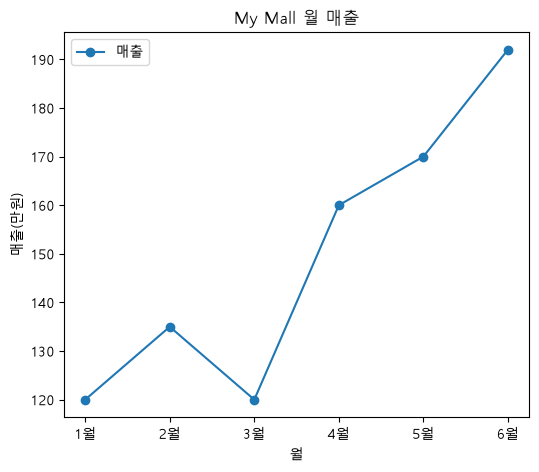

(300, 10)


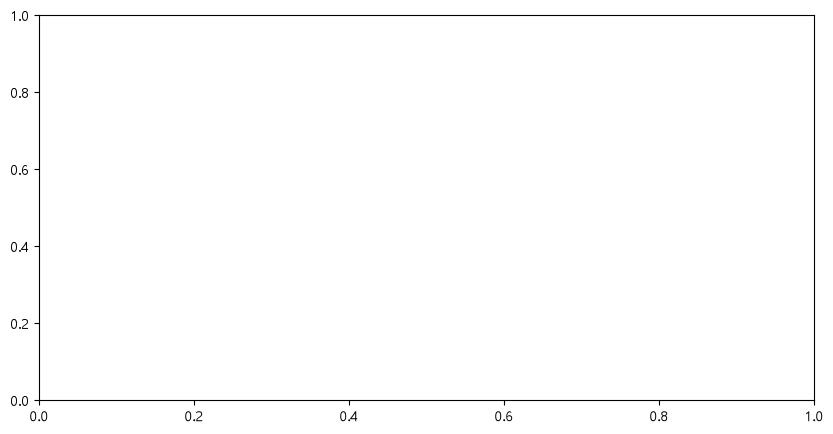

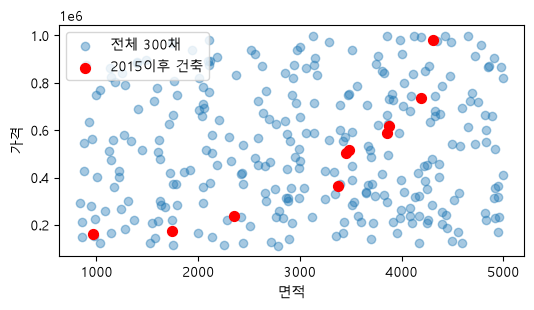

전체 300채의 상관계수: 0.08
10채의 상관계수: 0.89
기울기 w = 439.45870417134705 정답: 450
절편 b = 5926.680580056112 정답: 5000


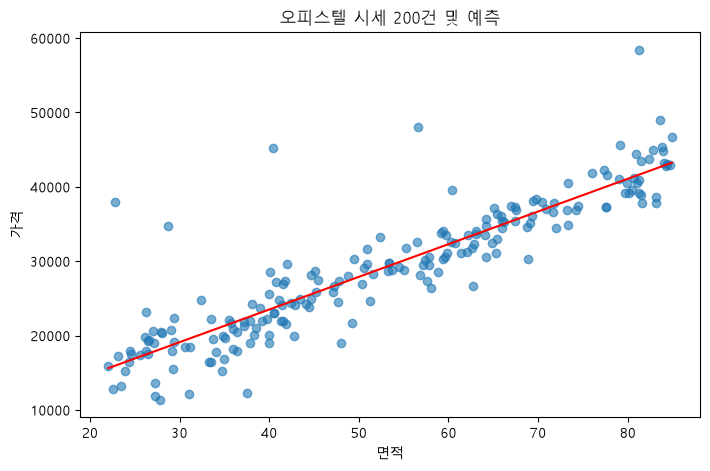

MAE = 2,493
MSE = 16,240,971
RMSE = 4,030
R_SCORE = 0.803
특이매물 [53 13  2 92 71]
정상매물 195
전체 200건 MAE 2492.503948887723 | RMSA 4030.0088601264406 | RScore 0.8034139611533421
특이매물 제외 195건 MAE 2075.1039768452683 | RMSA 2731.5353914457346 | RScore 0.9023854405903358


In [ ]:
# ==========================================
# 0. 라이브러리 및 한글 폰트 설정
# ==========================================
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

plt.rcParams["font.family"] = "Malgun Gothic"

# ==========================================
# 1. 월 매출 선 그래프 실습
# ==========================================

fig, ax = plt.subplots(figsize=(6, 5))
months = ["1월", "2월", "3월", "4월", "5월", "6월"]
sales = [120, 135, 120, 160, 170, 192]

ax.plot(months, sales, marker="o", label="매출")
ax.set_title("My Mall 월 매출")
ax.set_xlabel("월")
ax.set_ylabel("매출(만원)")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter

# ==========================================
# 2. 주택 데이터 산점도 및 상관계수
# ==========================================

house = pd.read_csv("./datasets/usa_housing.csv")
print(house.shape)

small = house[(house["YearBuilt"] > 2015) & (house["CrimeRate"] < 40)]
small.shape

plt.figure(figsize=(6, 3))
plt.scatter(house["SquareFeet"], house["Price"], alpha=0.4, label="전체 300채")
plt.scatter(small["SquareFeet"], small["Price"], color="red", s=50, label="2015이후 건축")
plt.xlabel("면적")
plt.ylabel("가격")
plt.legend()
plt.show()

print("전체 300채의 상관계수:", round(house["SquareFeet"].corr(house["Price"]),2))
print("10채의 상관계수:", round(small["SquareFeet"].corr(small["Price"]),2))
rng = np.random.default_rng(40)
n = 200
area = rng.uniform(20, 85, n)
price = (area * 450 + 5000 + rng.normal(0, 2500, n)).round(-1)
special = rng.choice(n, 5, replace=False)
price[special] += rng.uniform(15000, 25000, 5).round(-1)
office = pd.DataFrame({"area":area, "price":price})
office.describe().round(1)
office.to_csv("./datasets/office.csv", index=False)

office = pd.DataFrame({"area":area, "price":price})
office.describe().round(1)

X = office[["area"]]
y = office["price"]

model = LinearRegression()
model.fit(X, y)
print(f"기울기 w = {model.coef_[0]} 정답: 450")
print(f"절편 b = {model.intercept_} 정답: 5000")

new = pd.DataFrame({"area": [33, 59]})
model.predict(new).round(-1)

y_pred = model.predict(X)
line = X.sort_values("area")
line_pred = model.predict(line)

# ==========================================
# 3. 오피스텔 시세 생성, 선형회귀, 특이매물 영향 비교
# ==========================================

plt.figure(figsize=(8, 5))
plt.scatter(office["area"], office["price"], alpha=0.6, label="실제 시세")
plt.plot(line["area"], line_pred, color="red", label="모델의 직선")
plt.title("오피스텔 시세 200건 및 예측")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

print(f"MAE = {mean_absolute_error(y, y_pred):,.0f}")
print(f"MSE = {mean_squared_error(y, y_pred):,.0f}")
print(f"RMSE = {root_mean_squared_error(y, y_pred):,.0f}")
print(f"R_SCORE = {r2_score(y, y_pred):.3f}")

normal = np.ones(len(office), dtype=bool)
normal[special] = False
print("특이매물", special)
print("정상매물", normal.sum())

all_rows = np.ones(len(office), dtype=bool)
cases = [("전체 200건", all_rows), ("특이매물 제외 195건", normal)]

for name, mask in cases:
    y_true = y[mask]
    y_hat = y_pred[mask]

    mae = mean_absolute_error(y_true, y_hat)
    rmse = root_mean_squared_error(y_true, y_hat)
    r2 = r2_score(y_true, y_hat)
    print(f"{name} MAE {mae} | RMSA {rmse} | RScore {r2}")


## 02 수업 내용 뜯어먹기
===

### numpy, pandas, seaborn, matplotlib.pyplot 개념
- numpy: 다차원 배열과 벡터 연산을 빠르게 처리하는 수치 계산 기반 라이브러리 
- pandas: 행과 열로 구성된 DataFrame으로 데이터를 불러오고 정제하며 집계하는데 쓰임
- seaborn: Matplotlib을 기반으로 분포도, 박스플롯, 히트맵 등 통계 차트를 간결한 코드와 세련된 스타일로 그리는 고수준 시각화 라이브러리
- matplotlib: 선, 막대, 산점도 등 기본 그래프를 그리고 축, 제목, 레이아웃을 세밀하게 제어하는 저수준 시각화 엔진
- pyplot: Matplotlib의 서브패키지로서 2D그래프를 생성하고 제어함    

---

### Matplotlib에서 plt.rcParams로 한글 폰트 설정하기
- plt.rcParams['font.family'] = 'Malgun Gothic'
- plt는 matplotlib.pyplot 모듈을 줄여 부른것(alias)
- rcParams는 Matplotlib의 전역설정을 관리하는 딕셔너리 객체. 이 객체의 역할은 그래프를 그릴 때마다 매번 크기, 폰트, 선 두께 등을 지정하지 않고 기본값을 미리 정해둘때 사용 
- 'font.family'는 기본 글꼴을 의미

---

### Matplotlib에서 사용하는 Figure, axes 에 대하여
- Figure: 여러 개의 그래프를 담을 수 있는 전체 창이나 도화지. 전체크기, 배경색, 전체제목등을 다룸
- Axes: 실제 선, 막대, 산점도 등이 그려지는 플롯 영역. 하나의 Figure안에 여러 개의 Axes를 배치할 수 있음. 각 Axes는 자체 x축, y축(axis), 제목, 범례, 축 범위 등을 가짐 
- Axes와 Axis: Axis는 축 자체, Axes는 그래프 영역 

---

### Matplotlib에서 사용하는 Box plot 에 대하여
- 박스 플롯(Box plot): 전체 데이터로부터 얻어진 최소값, 제1사분위 수(Q1), 제2사분위 수 또는 중위수(Q2), 제 3사분위 수(Q3), 최대값 요약 수치를 사용해서 그린다
- 사분위 수: 데이터를 4등분한 지점을 의미. 예를 들어 제1사분위수는 전체 데이터 중 하위 25%에 해당하는 값, 제3사분위 수는 전체 데이터 중 상위 25%에 해당하는 값 
- Whisker(수염): 상자(Q1~Q3, 사분위수 범위 IQR) 바깥으로 뻗어 나온 선. 이상치를 제외한 데이터의 퍼짐 범위

---

### 머신러닝 중 선형 회귀 원리에 대하여
- 머신러닝(ML, 기계학습): 컴퓨터가 명시적인 규칙을 일일이 코딩하지 않고도 데이터에서 패턴을 학습해 예측이나 결정을 내리는 인공지능(Ai)의 한 분야
- 선형회귀(Linear Regression): 하나 이상의 독립 변수(입력/특성)와 연속형 종속 변수(출력/목표) 사이의 선형 관계를 직선 또는 초평면 방정식으로 모델링해 값을 예측하거나 관계를 설명하는 통계 및 머신러닝 기법 
- 선형(Linear): 직선처럼 똑바른 형태나 입력과 출력이 정비례하거나 순차적으로 이어지는 성질
- 회귀: 여러 자료들 간의 관계성을 수학적으로 그 중에서도 선형 모형으로 설명한다
- 기울기(가중치)와 절편(편향): 기울기는 직선이 기울어진 정도와 방향(x증가량 대비 y증가량), 절편은 그래프가 좌표축(x축, y축)과 만나는 점의 좌표. 
- 오차 줄이기: 실제 값과 예측 값의 차이(오차, 평균제곱오차 등)를 그래프로 보여 줄일때, 파라미터(가중치)를 조정해 오차 함수가 최솟값이 되는 지점을 찾는다 


---

### 머신러닝 회귀 모델 성능 평가 지표
- MAE(Mean Absolute Error, 평균 절대 오차): 실제 정답 값과 예측 값의 차이를 절댓값으로 변환한 뒤 합산하여 평균을 구함. 특이값이 많은 경우에 주로 사용. 값이 낮을수록 좋음. 
- MSE(Mean Squared Error, 평균 제곱 오차): 실제 정답 값과 예측 값의 차이를 제곱한 뒤 평균을 구함. 값이 낮을수록 좋음 
- RMSE(Root Mean Squared Error, 평균 제곱근 오차): MSE에 루트는 씌워서 에러를 제곱해서 생기는 값의 왜곡이 줄어듦. 값이 낮을수록 좋음. 
- MAPE(Mean Absolute Percentage Error, 평균 절대 비율 오차): MAE를 비율, 퍼센트로 표현하여 스케일 의존적 에러(예측값과 실제값의 차이를 원래 데이터의 단위 그대로 측정하는 오차 지표)의 문제점을 개선한다. 값이 낮을수록 좋다. 
- MPE(Mean Percentage Error): MAPE에서 절대값을 제외하여 계산. 모델이 underperformance인지 overperformance인지 판단할 수 있음 (음수이면 overperformance, 양수이면 underperformance)
- R2 score=R squart: 다른 지표(MAE, MSE, RMSE)들은 모델마다 값이 다르기 때문에 절대 값만 보고 선능을 판단하기 어려움. R2 score는 상대적인 성능을 나타내기 비교가 쉽다. 실제 값의 분산 대비 예측값의 분산 비율을 의미. 1에 가까울 수록 좋다 


---

### 난수생성과 시드
- 시드: 난수 생성기의 초기값(Starting Value). 컴퓨터에서 난수(Random Number)를 생성할때 완전한 무작위는 불가능하기에 특정한 초기값(Seed)를 설정해 유사 난수를 생성. 
- 쓰는이유: 동일한 프로그램을 여러 번 실행할 때 같은 난수를 얻고싶을 경우 시드를 고정
- 새로운 난수를 원한다면: 시드 값만 바꾸면 됨. 


---

### 사이킷런(scikit-learn)에 대해
- 사이킷런(scikit-learn): Numpy와 SciPy를 기반으로 구축된 대표적인 파이썬 오픈소스 머신러닝 라이브러리. 분류 및 회귀, 클러스터링 및 차원 축소, 전처리 및 파이프라인, 모델 선택 및 평가를 하는 기능을 가졌다. 
- fit(X, y=None): 사이킷런의 주요 메서드. 학습 데이터(X, 타깃y)를 기반으로 모델이나 전처리기를 학습. 비지도 학습이나 전처리에서는 y를 생략. 
- predict(X): 학습된 모델로 새 데이터(X)의 결과(분류 클래스, 회귀 값, 군집 번호 등)를 예측
- transform(X): 학습된 전처리기(스케일러, 인코더, 차원 축소 등)로 데이터(X)를 변환 
- fit_transform(X, y=None): fit()과 transform()을 한 번에 수행. 주로 학습 데이터 전처리에 사용
- score(X, y): 모델의 기본 성능 점수(분류는 정확도, 회귀는 결정계수 R2 등)를 계산해 반환 

---

### 사이킷런(scikit-learn) 함수종류
01 데이터 로드 및 분할
- load_iris(), load_breast_cancer(), fetch_california_housing(): 내장 또는 외부 예제 데이터를 불러옴 
- make_classification(): 분류용 가상 데이터를 생성
- train_test_split(X, y, test_size=..., random_state=...): 데이터를 학습용과 테스트용으로 분할 

02 전처리 및 변환(fit, transform)
- StandardScaler, MinMaxScaler: 피처 스케일링을 수행 
- fit(X): 데이터에서 변환 기준(평균, 분산, 최솟값, 최댓값 등)을 학습 
- transform(X) / fit_transform(X): 학습한 기준으로 데이터를 변환 

03 모델 학습 및 예측(fit, predict, score)
- model.fit(X_train, y_train): 입력 피처와 정답데이터로 모델을 학습
- model.predict(X_test): 학습된 모델로 새로운 데이터의 결과를 예측
- model.score(X_test, y_test): 모델의 기본 평가 점수(분류는 정확도, 회귀는 결정계수 등)르르 반환 

04 검증, 튜닝 및 파이프라인 
- cross_val_score(model, X, y, cv=5): 교차 검증 점수를 계산
- GridSearchCV(model, param_grid, cv=5): 하이퍼파라미터 조합을 탐색해 최적 모델을 찾음 
- Pipeline / make_pipeline: 전처리와 모델 학습 과정을 하나로 묶어 데이터 누수를 줄이고 워크플로를 단순화 

05 성능 평가 
- confusion_matrix(y_true, y_pred): 혼동 행렬을 계산
- classification_report(y_true, y_pred): 정밀도, 재현율, F1점수 등 분류 지표를 요약 


## 03 오늘 만난 에러
===

1. fig, ax = plt.subplot(figsize=(6, 5))    
> 오타이슈: subplots라고 해야했는데, 복수형 s를 빼먹었음

2. ax.legnd()
> 오타이슈: legend라고 해야했는데, g다음에 e를 빼먹었음 

3. plt.fiqure(figsize=(6, 3))
> 오타이슈: figure라고 해야했는데 g를 q로 적음

4. office.to.csv("./datasets/office.csv", index=False)
> 오타이슈: to_csv인데, _를 .이라고 적음 

5. 그밖에 거의 많은 오류가 오타로 인한 오류였음

## 04 Today's Brain Status
===

* **개념 이해도:** 20% (튜터님 따라 눈과 손만 따라간게 전부고, 아직 뭐가 뭔지 잘 모르겠음)
* **코드 구현도:** 10% (아직 안 보고 치기 어려운 수준)
* **잔여 배터리:** 20% (20시까지 복습할정도)
* **오늘의 병목:** `plt.rcParams` 문법 오류 및 변수명(`y_pred`) 혼동으로 시간 소요
* **나를 위한 과제:** 일단 오늘 배운 내용을 반복적으로 보고 듣고 학습하자

## 05 수업후기
===        
일단은 머신러닝과 관련된 내용들은 어려운 내용들이 많아서 이해하려면 최대한 많이 보고 많이 듣고 그렇게 해서 학습수준을 향상해나가야할것같습니다. 그래도 눈과 손은 튜터님을 따라가는데 어려움은 없었습니다.